# Анализ данных и визуализация
**Дисциплина:** Спецглавы баз данных. **Данные:** клиенты банка.

**Источник:** [тетрадка вебинара](https://colab.research.google.com/drive/1wnP5RDyemAB2ATtckQvUnsOEVn20kbv_).
Исходный файл `bank_dataset.xlsx` преобразуется в JSON без очистки и загружается
в файловую базу SQLite. Далее данные выгружаются в pandas для анализа по городам.

In [1]:
import importlib.util
import subprocess
import sys

# В Colab библиотеки обычно уже установлены.
packages = {"pandas": "pandas>=2.2,<3", "numpy": "numpy>=1.26,<3",
            "matplotlib": "matplotlib>=3.8,<4", "openpyxl": "openpyxl>=3.1,<4"}
missing = [requirement for module, requirement in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import hashlib
import json
import sqlite3
import urllib.request
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 20)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})
DATA_DIR = Path(".")
RESULTS = DATA_DIR / "results"
RESULTS.mkdir(exist_ok=True)
DB_PATH = DATA_DIR / "bank_analysis.sqlite3"
print("pandas:", pd.__version__, "SQLite:", sqlite3.sqlite_version)

pandas: 2.3.3 SQLite: 3.54.0


## 1. Подготовка JSON и загрузка в SQLite

SHA-256 фиксирует версию исходного файла.
Пустые значения Excel сохраняются в JSON как `null`, затем в SQLite как `NULL`.

In [2]:
SOURCE_URL = "https://drive.google.com/uc?export=download&id=10OSA8ENKfan8mJrNgCmio8-q0qJkaPIy"
SOURCE_SHA256 = "8b432a9dc2f119b45c4b4a628f6be9a24697786fa1d60ef2f8c27cf0c4bd9b61"
xlsx_path = DATA_DIR / "bank_dataset.xlsx"
json_path = DATA_DIR / "bank_dataset.json"
if not xlsx_path.exists():
    with urllib.request.urlopen(SOURCE_URL, timeout=60) as response:
        source_bytes = response.read()
    if hashlib.sha256(source_bytes).hexdigest() != SOURCE_SHA256:
        raise ValueError("Скачан другой файл. Проверьте доступ и версию данных преподавателя.")
    xlsx_path.write_bytes(source_bytes)
assert hashlib.sha256(xlsx_path.read_bytes()).hexdigest() == SOURCE_SHA256, "Версия Excel изменилась"

source = pd.read_excel(xlsx_path, engine="openpyxl")
source.to_json(json_path, orient="records", force_ascii=False, indent=2, double_precision=15)
records = json.loads(json_path.read_text(encoding="utf-8"))
assert len(records) == len(source)
print(f"Excel → JSON: {len(records):,} записей, {len(source.columns)} столбцов")
print("Поля:", ", ".join(source.columns))

Excel → JSON: 10,000 записей, 16 столбцов
Поля: userid, score, city, gender_male, age, objects, balance, products, credit_card, loyalty, estimated_salary, churn, rostov_velikij, rybinsk, jaroslavl, no_balance


In [3]:
# Первичный ключ намеренно не задаём: сырые данные должны сохранять возможные дубликаты.
columns = ["userid", "score", "city", "gender_male", "age", "objects", "balance",
           "products", "credit_card", "loyalty", "estimated_salary", "churn",
           "rostov_velikij", "rybinsk", "jaroslavl", "no_balance"]
assert list(source.columns) == columns
with closing(sqlite3.connect(DB_PATH)) as connection:
    with connection:
        connection.execute("""
            CREATE TABLE IF NOT EXISTS clients_raw (
                userid INTEGER, score INTEGER, city TEXT, gender_male INTEGER,
                age INTEGER, objects INTEGER, balance REAL, products INTEGER,
                credit_card INTEGER, loyalty INTEGER, estimated_salary REAL,
                churn INTEGER, rostov_velikij INTEGER, rybinsk INTEGER,
                jaroslavl INTEGER, no_balance INTEGER
            )
        """)
        # Повторный запуск заменяет данные только этой учебной таблицы.
        connection.execute("DELETE FROM clients_raw")
        connection.executemany(
            "INSERT INTO clients_raw VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)",
            [tuple(record[column] for column in columns) for record in records],
        )
    loaded_count = connection.execute("SELECT COUNT(*) FROM clients_raw").fetchone()[0]
assert loaded_count == len(records)
print(f"В SQLite загружено {loaded_count:,} строк. Соединение закрыто.")

В SQLite загружено 10,000 строк. Соединение закрыто.


## 2. Новое подключение и выгрузка в pandas

Одна строка — один клиент. Группировка выполняется по `city`.
Идентификатор `userid` исключён из числовых статистик.
Показатели: `score`, `age`, `objects`, `balance`, `products`, `estimated_salary`.
Остальные числовые поля — бинарные признаки; их среднее соответствует доле единиц.
Валюта в источнике не указана, поэтому денежные показатели подписаны «ден. ед.».

In [4]:
with closing(sqlite3.connect(DB_PATH)) as connection:
    df = pd.read_sql_query("SELECT * FROM clients_raw ORDER BY rowid", connection)
pd.testing.assert_frame_equal(df, source, check_dtype=False)
print("Размер таблицы:", df.shape)
display(df.head())
display(pd.DataFrame({"тип": df.dtypes.astype(str), "пропуски": df.isna().sum()}))

Размер таблицы: (10000, 16)


,userid,score,city,gender_male,age,objects,balance,products,credit_card,loyalty,estimated_salary,churn,rostov_velikij,rybinsk,jaroslavl,no_balance
0,15677338,619,Ярославль,0,42,2,NaN,1,1,1,101348.88,1,0,0,1,1
1,15690047,608,Рыбинск,0,41,1,83807.86,1,0,1,112542.58,0,0,1,0,0
2,15662040,502,Ярославль,0,42,8,159660.80,3,1,0,113931.57,1,0,0,1,0
3,15744090,699,Ярославль,0,39,1,NaN,2,0,0,93826.63,0,0,0,1,1
4,15780624,850,Рыбинск,0,43,2,125510.82,1,1,1,79084.10,0,0,1,0,0


,тип,пропуски
userid,int64,0
score,int64,0
city,object,0
gender_male,int64,0
age,int64,0
objects,int64,0
balance,float64,3617
products,int64,0
credit_card,int64,0
loyalty,int64,0


## 3. Очистка данных

Удаляются внешние пробелы в названиях городов и полные дубликаты строк.
После этого проверяется уникальность `userid`.

Пропуски баланса сохраняются: клиент участвует в расчёте остальных показателей,
но не статистик баланса. Количество известных балансов учитывается отдельно.

Выбросы определяются внутри каждого города по `score`, `age`, `balance`, `estimated_salary`.
Границы: `Q1 − 1.5 × IQR` и `Q3 + 1.5 × IQR`, где `IQR = Q3 − Q1`.
Строка исключается, если хотя бы одно известное значение выходит за границы.
Все границы вычисляются до удаления строк. При нулевом IQR или менее четырёх
известных значений фильтр не применяется.

Идентификаторы, бинарные признаки и счётчики `objects`/`products` не фильтруются по IQR.
Статистический выброс может быть реальным наблюдением. Влияние фильтрации оценивается
сравнением оттока до и после очистки.

In [5]:
normalized = df.copy()
normalized["city"] = normalized["city"].astype("string").str.strip().replace("", pd.NA)
duplicate_mask = normalized.duplicated()
duplicates = normalized.loc[duplicate_mask].copy()
deduplicated = normalized.loc[~duplicate_mask].copy()
assert deduplicated["userid"].notna().all()
assert deduplicated["userid"].is_unique, "Есть конфликтующие записи одного клиента"

numeric_columns = [column for column in columns if column not in ["userid", "city"]]
numeric_values = deduplicated[numeric_columns].to_numpy(dtype=float)
assert not np.isinf(numeric_values).any(), "Обнаружены бесконечные значения"
required = [column for column in columns if column != "balance"]
assert deduplicated[required].notna().all().all(), "Есть неожиданные пропуски; нужна отдельная проверка"
flags = ["gender_male", "credit_card", "loyalty", "churn", "rostov_velikij",
         "rybinsk", "jaroslavl", "no_balance"]
assert deduplicated[flags].isin([0, 1]).all().all()
assert deduplicated["no_balance"].astype(bool).equals(deduplicated["balance"].isna())

display(pd.DataFrame({
    "клиентов": deduplicated.groupby("city").size(),
    "баланс_известен": deduplicated.groupby("city")["balance"].count(),
    "баланс_пропущен": deduplicated.groupby("city")["balance"].agg(lambda s: s.isna().sum()),
}))
print("Полных дубликатов удалено:", len(duplicates))

,клиентов,баланс_известен,баланс_пропущен
city,,,
Ростов Великий,2509,2509,0
Рыбинск,2477,1278,1199
Ярославль,5014,2596,2418


Полных дубликатов удалено: 0


In [6]:
outlier_columns = ["score", "age", "balance", "estimated_salary"]
outlier_flags = pd.DataFrame(False, index=deduplicated.index, columns=outlier_columns)
bounds_rows = []
for city, group in deduplicated.groupby("city", sort=True):
    for column in outlier_columns:
        values = group[column].dropna()
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        active = len(values) >= 4 and iqr > 0
        marked = (group[column].lt(lower) | group[column].gt(upper)) if active else pd.Series(False, index=group.index)
        outlier_flags.loc[group.index, column] = marked
        bounds_rows.append({"city": city, "column": column, "n": len(values),
                            "q1": q1, "q3": q3, "lower": lower, "upper": upper,
                            "outliers": int(marked.sum()), "filter_active": active})

bounds = pd.DataFrame(bounds_rows)
outlier_mask = outlier_flags.any(axis=1)
excluded = deduplicated.loc[outlier_mask].copy()
excluded["outlier_columns"] = outlier_flags.loc[outlier_mask].apply(
    lambda row: ", ".join(row.index[row]), axis=1)
clean = deduplicated.loc[~outlier_mask].copy()
assert not clean.empty
assert len(df) == len(duplicates) + len(excluded) + len(clean)
assert clean["userid"].is_unique
display(bounds.round(2))
audit = pd.DataFrame({"этап": ["Исходные строки", "Полные дубликаты", "Строки с выбросами", "Осталось"],
                      "строк": [len(df), len(duplicates), len(excluded), len(clean)]})
display(audit)
print("Числа выбросов по столбцам могут пересекаться; в отчёте строка учитывается один раз.")
display(excluded[["userid", "city", *outlier_columns, "outlier_columns"]].head(10))

,city,column,n,q1,q3,lower,upper,outliers,filter_active
0,Ростов Великий,score,2509,584.00,722.00,377.00,929.00,4,True
1,Ростов Великий,age,2509,32.00,45.00,12.50,64.50,70,True
2,Ростов Великий,balance,2509,102800.72,137560.38,50661.23,189699.87,33,True
3,Ростов Великий,estimated_salary,2509,51016.02,151083.80,-99085.65,301185.47,0,True
4,Рыбинск,score,2477,587.00,715.00,395.00,907.00,7,True
5,Рыбинск,age,2477,32.00,44.00,14.00,62.00,93,True
6,Рыбинск,balance,1278,98066.69,140342.13,34653.54,203755.29,16,True
7,Рыбинск,estimated_salary,2477,50267.69,147278.43,-95248.42,292794.54,0,True
8,Ярославль,score,5014,582.00,717.00,379.50,919.50,6,True
9,Ярославль,age,5014,31.00,43.00,13.00,61.00,206,True


,этап,строк
0,Исходные строки,10000
1,Полные дубликаты,0
2,Строки с выбросами,449
3,Осталось,9551


Числа выбросов по столбцам могут пересекаться; в отчёте строка учитывается один раз.


,userid,city,score,age,balance,estimated_salary,outlier_columns
7,15698884,Ростов Великий,376,29,115046.74,119346.88,score
58,15666680,Рыбинск,511,66,NaN,1643.11,age
85,15847990,Рыбинск,652,75,NaN,114675.75,age
104,15847655,Рыбинск,670,65,NaN,177655.68,age
138,15637144,Рыбинск,584,48,213146.20,75161.25,balance
158,15632711,Ярославль,646,73,97259.25,104719.66,age
177,15833091,Ростов Великий,606,36,190479.48,179351.89,balance
181,15832405,Ярославль,510,65,NaN,48071.61,age
230,15851209,Ярославль,673,72,NaN,111981.19,age
234,15747505,Ярославль,585,67,113978.97,93146.11,age


## 4. Статистики по категориям

Для числовых полей, кроме идентификатора, рассчитываются количество известных значений,
среднее, медиана, выборочное стандартное отклонение (`ddof=1`), минимум и максимум.
Отток — доля клиентов с `churn=1`.

In [7]:
statistics = clean.groupby("city")[numeric_columns].agg(["count", "mean", "median", "std", "min", "max"])
# Длинный формат удобнее для чтения, чем таблица с 84 столбцами.
statistics_long = statistics.stack(level=0, future_stack=True)
statistics_long.index.names = ["city", "metric"]
display(statistics_long.round(2))

summary = clean.groupby("city").agg(
    clients=("userid", "size"), balance_count=("balance", "count"),
    mean_balance=("balance", "mean"), median_balance=("balance", "median"),
    mean_salary=("estimated_salary", "mean"), mean_age=("age", "mean"),
    mean_score=("score", "mean"), churn_rate=("churn", "mean"),
)
summary["churn_pct"] = summary["churn_rate"] * 100
summary["missing_balance_pct"] = (1 - summary["balance_count"] / summary["clients"]) * 100
display(summary.round(2))

sensitivity = pd.DataFrame({
    "clients_before": deduplicated.groupby("city").size(),
    "clients_after": clean.groupby("city").size(),
    "churn_before_pct": deduplicated.groupby("city")["churn"].mean() * 100,
    "churn_after_pct": summary["churn_pct"],
})
sensitivity["removed_pct"] = (1 - sensitivity["clients_after"] / sensitivity["clients_before"]) * 100
sensitivity["churn_change_pp"] = sensitivity["churn_after_pct"] - sensitivity["churn_before_pct"]
display(sensitivity.round(2))

count       mean     median       std  \
city           metric                                                    
Ростов Великий score              2404     651.88     651.00     97.84   
               gender_male        2404       0.52       1.00      0.50   
               age                2404      38.91      38.00      9.20   
               objects            2404       5.01       5.00      2.94   
               balance            2404  119913.49  119771.38  25532.45   
               products           2404       1.52       1.00      0.62   
               credit_card        2404       0.71       1.00      0.45   
               loyalty            2404       0.49       0.00      0.50   
               estimated_salary   2404  101154.20  102321.61  58289.98   
               churn              2404       0.33       0.00      0.47   
               rostov_velikij     2404       1.00       1.00      0.00   
               rybinsk            2404       0.00       0.00      0.00   
               jaroslavl          2404       0.00       0.00      0.00   
               no_balance         2404       0.00       0.00      0.00   
Рыбинск        score              2361     652.10     651.00     93.36   
               gender_male        2361       0.56       1.00      0.50   
               age                2361      37.70      37.00      8.73   
               objects            2361       5.04       5.00      2.85   
               balance            1206  119312.71  119195.79  30868.71   
               products           2361       1.54       2.00      0.56   
               credit_card        2361       0.69       1.00      0.46   
               loyalty            2361       0.52       1.00      0.50   
               estimated_salary   2361   99122.85   99595.67  57145.78   
               churn              2361       0.16       0.00      0.37   
               rostov_velikij     2361       0.00       0.00      0.00   
               rybinsk            2361       1.00       1.00      0.00   
               jaroslavl          2361       0.00       0.00      0.00   
               no_balance         2361       0.49       0.00      0.50   
Ярославль      score              4786     649.67     653.00     96.29   
               gender_male        4786       0.55       1.00      0.50   
               age                4786      37.21      36.00      8.52   
               objects            4786       5.01       5.00      2.88   
               balance            2473  119940.58  120124.35  30927.82   
               products           4786       1.53       1.00      0.57   
               credit_card        4786       0.71       1.00      0.45   
               loyalty            4786       0.50       1.00      0.50   
               estimated_salary   4786   99977.60   99072.74  57327.32   
               churn              4786       0.16       0.00      0.37   
               rostov_velikij     4786       0.00       0.00      0.00   
               rybinsk            4786       0.00       0.00      0.00   
               jaroslavl          4786       1.00       1.00      0.00   
               no_balance         4786       0.48       0.00      0.50   

                                      min        max  
city           metric                                 
Ростов Великий score               395.00     850.00  
               gender_male           0.00       1.00  
               age                  18.00      64.00  
               objects               0.00      10.00  
               balance           50880.98  188976.89  
               products              1.00       4.00  
               credit_card           0.00       1.00  
               loyalty               0.00       1.00  
               estimated_salary     11.58  199970.74  
               churn                 0.00       1.00  
               rostov_velikij        1.00       1.00  
               rybinsk               0.00       0.00  
      

,clients,balance_count,mean_balance,median_balance,mean_salary,mean_age,mean_score,churn_rate,churn_pct,missing_balance_pct
city,,,,,,,,,,
Ростов Великий,2404,2404,119913.49,119771.38,101154.20,38.91,651.88,0.33,32.82,0.00
Рыбинск,2361,1206,119312.71,119195.79,99122.85,37.70,652.10,0.16,16.01,48.92
Ярославль,4786,2473,119940.58,120124.35,99977.60,37.21,649.67,0.16,15.86,48.33


,clients_before,clients_after,churn_before_pct,churn_after_pct,removed_pct,churn_change_pp
city,,,,,,
Ростов Великий,2509,2404,32.44,32.82,4.18,0.38
Рыбинск,2477,2361,16.67,16.01,4.68,-0.66
Ярославль,5014,4786,16.15,15.86,4.55,-0.30


## 5. Столбиковые диаграммы

На диаграмме баланса `n` — число известных балансов, на остальных — число клиентов
после очистки. Разная доля пропусков по городам может влиять на сравнение балансов.

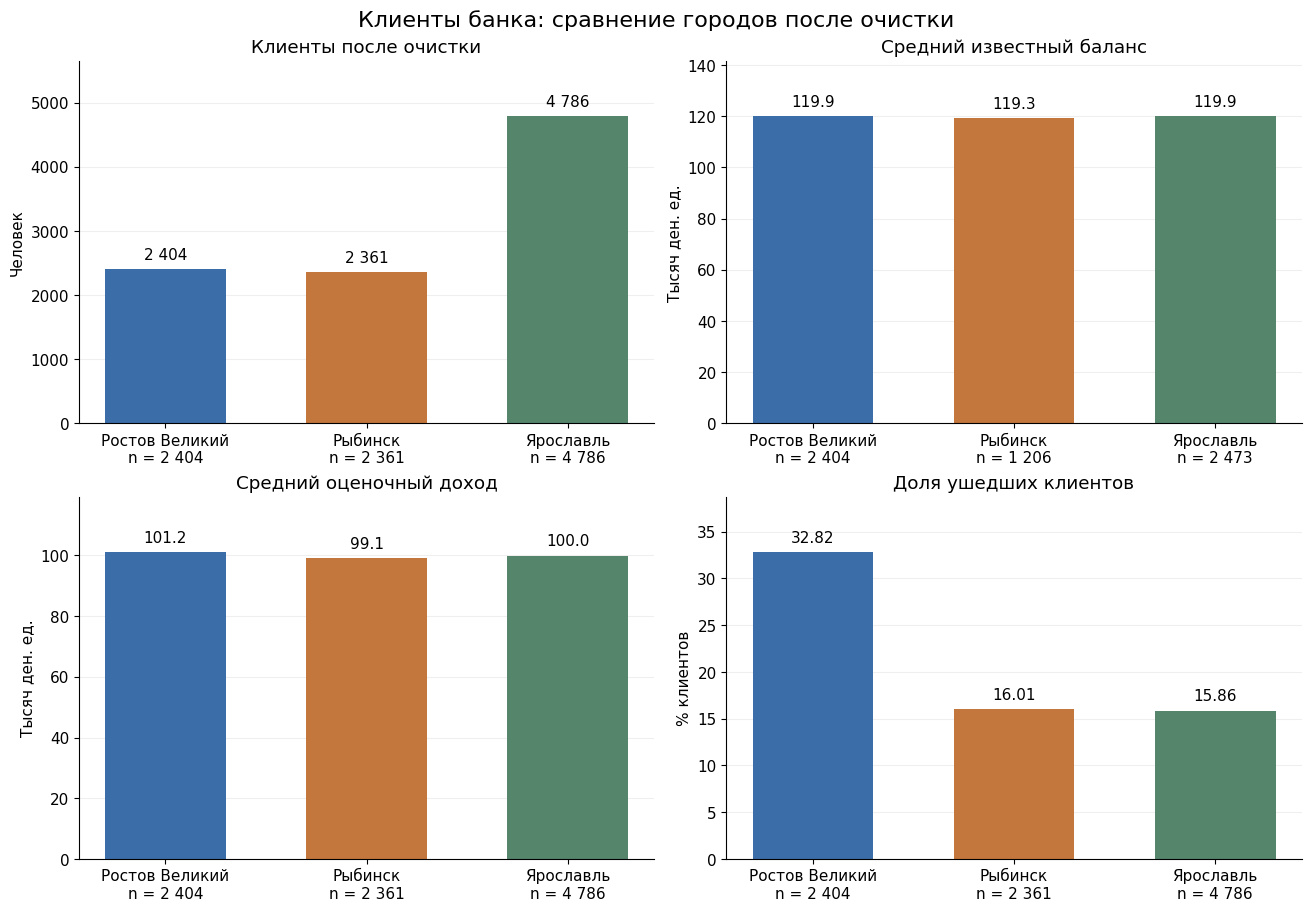

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")
colors = ["#3B6EA8", "#C4773C", "#55856B"]
panels = [
    ("clients", "Клиенты после очистки", "Человек", 1, 0),
    ("mean_balance", "Средний известный баланс", "Тысяч ден. ед.", 1000, 1),
    ("mean_salary", "Средний оценочный доход", "Тысяч ден. ед.", 1000, 1),
    ("churn_pct", "Доля ушедших клиентов", "% клиентов", 1, 2),
]
for ax, (metric, title, ylabel, divisor, decimals) in zip(axes.flat, panels):
    values = summary[metric] / divisor
    bars = ax.bar(summary.index, values, color=colors, width=0.6)
    ax.bar_label(bars, labels=[f"{value:,.{decimals}f}".replace(",", " ") for value in values], padding=5)
    counts = summary["balance_count"] if metric == "mean_balance" else summary["clients"]
    ax.set_xticks(range(len(summary)), [f"{city}\nn = {int(counts.loc[city]):,}".replace(",", " ") for city in summary.index])
    ax.set(title=title, ylabel=ylabel, ylim=(0, values.max() * 1.18))
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Клиенты банка: сравнение городов после очистки", fontsize=16)
fig.savefig(RESULTS / "city_analysis.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Выводы

In [9]:
largest_city = summary["clients"].idxmax()
highest_churn = summary["churn_pct"].idxmax()
lowest_churn = summary["churn_pct"].idxmin()
salary_city = summary["mean_salary"].idxmax()
churn_gap = summary.loc[highest_churn, "churn_pct"] - summary.loc[lowest_churn, "churn_pct"]
salary_spread = (summary["mean_salary"].max() / summary["mean_salary"].min() - 1) * 100
missing_balance = int(clean["balance"].isna().sum())
conclusions = f"""
1. Из JSON в SQLite загружено **{len(df):,} строк**. Полных дубликатов: **{len(duplicates)}**.
   По правилу IQR исключено **{len(excluded)} строк ({len(excluded) / len(deduplicated):.2%})**;
   осталось **{len(clean):,} клиентов**. Отсутствие дублей не означает, что проверку можно пропустить.
2. Самая большая группа после очистки — **{largest_city}: {int(summary.loc[largest_city, 'clients']):,} клиентов**
   ({summary.loc[largest_city, 'clients'] / len(clean):.2%} выборки).
3. Наибольшая доля ушедших — **{highest_churn}: {summary.loc[highest_churn, 'churn_pct']:.2f}%**,
   наименьшая — **{lowest_churn}: {summary.loc[lowest_churn, 'churn_pct']:.2f}%**.
   Разница составляет **{churn_gap:.2f} процентного пункта**.
4. Наибольший средний оценочный доход — **{salary_city}: {summary.loc[salary_city, 'mean_salary']:,.2f} ден. ед.**
   Разница между максимальным и минимальным средним доходом составляет **{salary_spread:.2f}% от минимума**.
   Эти описательные сравнения сами по себе не устанавливают статистическую значимость.
5. Баланс неизвестен у **{missing_balance:,} клиентов ({missing_balance / len(clean):.2%})**.
   Средние и медианы баланса характеризуют только клиентов с известными значениями.
   Если пропуски неслучайны, выводы о балансах всех клиентов могут быть смещены.
6. Максимальное изменение оттока по городу после IQR-фильтра —
   **{sensitivity['churn_change_pp'].abs().max():.2f} п. п. по модулю**.
   Фильтр удаляет также возможные реальные крайние значения и меняет состав выборки.
   Различия между городами описывают эту выборку; причины оттока по ним установить нельзя.
"""
display(Markdown(conclusions))
(RESULTS / "conclusions.md").write_text(conclusions.strip() + "\n", encoding="utf-8")


1. Из JSON в SQLite загружено **10,000 строк**. Полных дубликатов: **0**.
   По правилу IQR исключено **449 строк (4.49%)**;
   осталось **9,551 клиентов**. Отсутствие дублей не означает, что проверку можно пропустить.
2. Самая большая группа после очистки — **Ярославль: 4,786 клиентов**
   (50.11% выборки).
3. Наибольшая доля ушедших — **Ростов Великий: 32.82%**,
   наименьшая — **Ярославль: 15.86%**.
   Разница составляет **16.96 процентного пункта**.
4. Наибольший средний оценочный доход — **Ростов Великий: 101,154.20 ден. ед.**
   Разница между максимальным и минимальным средним доходом составляет **2.05% от минимума**.
   Эти описательные сравнения сами по себе не устанавливают статистическую значимость.
5. Баланс неизвестен у **3,468 клиентов (36.31%)**.
   Средние и медианы баланса характеризуют только клиентов с известными значениями.
   Если пропуски неслучайны, выводы о балансах всех клиентов могут быть смещены.
6. Максимальное изменение оттока по городу после IQR-фильтра —
   **0.66 п. п. по модулю**.
   Фильтр удаляет также возможные реальные крайние значения и меняет состав выборки.
   Различия между городами описывают эту выборку; причины оттока по ним установить нельзя.


1204

## Сохранение результатов и проверка

Исходная таблица `clients_raw` остаётся в базе, очищенная сохраняется отдельно как
`clients_clean`. Исключённые строки с причиной, границы IQR и статистики сохраняются в `results`.

In [10]:
with closing(sqlite3.connect(DB_PATH)) as connection:
    clean.to_sql("clients_clean", connection, if_exists="replace", index=False)
    sql_summary = pd.read_sql_query("""
        SELECT city, COUNT(*) AS clients, COUNT(balance) AS balance_count,
               AVG(balance) AS mean_balance, AVG(churn) AS churn_rate
        FROM clients_clean GROUP BY city ORDER BY city
    """, connection).set_index("city")
sql_summary.index = sql_summary.index.astype(summary.index.dtype)
pd.testing.assert_frame_equal(sql_summary, summary[sql_summary.columns], check_dtype=False,
                              check_exact=False, rtol=1e-10, atol=1e-8)
assert int(summary["clients"].sum()) == len(clean)
assert int(summary["balance_count"].sum()) == int(clean["balance"].notna().sum())
assert len(clean) + len(excluded) + len(duplicates) == len(df)

statistics_long.to_csv(RESULTS / "statistics_by_city.csv", encoding="utf-8-sig")
summary.to_csv(RESULTS / "summary_by_city.csv", encoding="utf-8-sig")
sensitivity.to_csv(RESULTS / "filter_sensitivity.csv", encoding="utf-8-sig")
bounds.to_csv(RESULTS / "iqr_bounds.csv", index=False, encoding="utf-8-sig")
audit.to_csv(RESULTS / "cleaning_audit.csv", index=False, encoding="utf-8-sig")
excluded.to_csv(RESULTS / "excluded_outliers.csv", index=False, encoding="utf-8-sig")
duplicates.to_csv(RESULTS / "excluded_duplicates.csv", index=False, encoding="utf-8-sig")
print("Проверки пройдены: JSON → SQLite → pandas, баланс строк и сверка агрегаций с SQL.")
print("Файлы результатов:", ", ".join(path.name for path in sorted(RESULTS.iterdir())))

Проверки пройдены: JSON → SQLite → pandas, баланс строк и сверка агрегаций с SQL.
Файлы результатов: city_analysis.png, cleaning_audit.csv, conclusions.md, excluded_duplicates.csv, excluded_outliers.csv, filter_sensitivity.csv, iqr_bounds.csv, statistics_by_city.csv, summary_by_city.csv
